In [1]:
import keras_ocr
from tensorflow import keras
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
image_file = "Images/image_50402305.JPG"

In [3]:
tf_img = tf.io.read_file("Images/image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [4]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("Images/image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5
Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
8/8 [==============================] - 45s 5s/step


In [5]:
prediction_groups = prediction_groups[0]

---

In [7]:
# Define functions for dealing with images

image_width = 128
image_height = 32

def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

def DisplayWord(word):
    word = tf.reshape(word, (128, 32, 1))
    
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

The word is identified as:  slepy
538 994 96 163


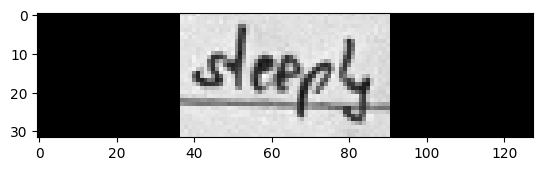

In [12]:
res = WordBox(prediction_groups[57])
DisplayWord(res)

In [13]:
word = res # This will be processed in the below code

# Pre-processing

In [14]:
from skimage.morphology import medial_axis, skeletonize, thin

from skimage.util import invert
import skimage

Make the image black background on white

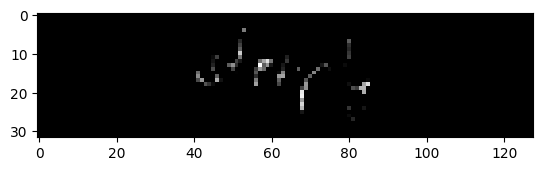

In [44]:
def BgChange(word):

    CleaningCoefficient = 6 # The higher this value, the more of the dimmer features that are cleaned out

    image = [ [ 0 for i in range(len(word[i])) ]  for i in range(len(word))]

    for i in range(len(word)):
        for j in range(len(word[i])):
            # if word[i][j][0] > 0.6:
            #     tf.print(word[i][j][0])
            #     image[i][j] = [1]
            # else:
            #     image[i][j] = [0]

            temp = float(word[i][j][0]) * CleaningCoefficient

            if temp == 0:
                temp = 1

            if temp > 1:
                temp = 1

            image[i][j] = temp

    image = tf.constant(image)

    image = skimage.img_as_float(image)
    image = invert(image)

    DisplayWord(image)

    return image
    
image = BgChange(word)

Slant removal

In [ ]:
# Begin from the findings from the paper

Make the characters 1 pixel wide

In [37]:
skeleton = thin(image, max_num_iter=1)

# or skeletonize(image)

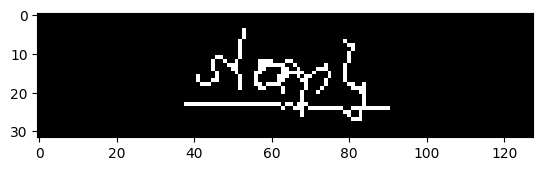

In [38]:
DisplayWord(skeleton)

In [32]:
skel, distance = medial_axis(image, return_distance=True)

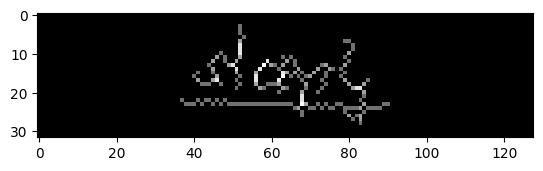

In [33]:
dist_on_skel = distance * skel
DisplayWord(dist_on_skel)

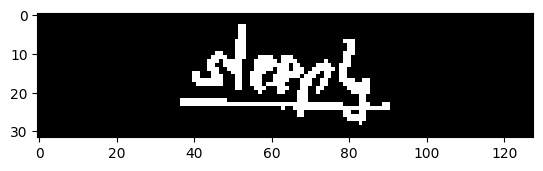

In [34]:
def convert_non_zero_to_one(tensor):
    # Create a boolean mask for non-zero values
    non_zero_mask = tf.math.not_equal(tensor, 0)
    
    # Convert non-zero values to 1 using the boolean mask
    result_tensor = tf.where(non_zero_mask, 1, tensor)
    
    return result_tensor

DisplayWord(convert_non_zero_to_one(image))